# FastMCP 로컬 서버 제작

**이 노트북에서 할 일**

1. 서버 객체를 만들고, 데코레이터 줄 하나로 함수를 도구로 붙입니다.
2. 힌트와 독스트링 없이 붙인 도구에 글이 아닌 값을 넣어, 그 값이 몸통까지 가는지 봅니다.
3. 힌트와 독스트링을 적어 붙인 도구에 같은 값을 넣어, 몸통 전에 거절되는지 봅니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
출력은 모두 서버와 클라이언트가 주고받은 값이라, 다시 실행해도 같은 값이 나와야 합니다.

서버는 노트북 안에서 클래스 `FastMCP`로 만들고, 01절처럼 같은 노트북 안에서 메모리로 연결합니다.
그래서 네트워크와 포트, 다른 프로그램을 쓰지 않습니다.
6절에서는 실습 폴더 맨 위의 `course_server.py` 파일을 읽기만 하고, 쓰는 파일은 없습니다.

걸린 시간은 재지 않았습니다.
이 절은 앞 챕터에서 배운 함수를 쓰지 않아, 가져오는 도구 파일도 없습니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
판은 fastmcp 4.0.3과 mcp 2.2.0입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽습니다.
도구를 붙이는 줄과, 힌트가 잘못된 값을 멈추는 자리를 Before·After로 보는 자리입니다.
5·6절은 넣는 값을 바꿔 보고 서버 파일의 줄을 읽는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch28-mcp`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 파란 상자 우리가 쓴 함수 lookup_policy 매개변수 topic: str 독스트링 한 줄에서, 파란 상자 데코레이터 줄 @after.tool 서버 after에 도구로 붙임으로, 다시 초록 상자 서버 객체 after 힌트 있는 자료실로 화살표가 갑니다. 그 아래에 클라이언트가 받은 도구 정의라는 칸이 있고, 칸 안에 노란 상자 셋 도구 이름 lookup_policy, 도구 설명 독스트링 글, 입력 형식 topic 칸 type string이 위에서 아래로 놓인 그림](attachment:02-1-함수의-세-부분과-도구-정의.png)

위에서 아래로 읽습니다.
파란 상자 둘은 노트북 4절에서 우리가 쓴 함수와 데코레이터 줄이고, 초록 상자는 그 줄이 도구를 올린 서버 객체입니다.
칸 안 노란 상자 셋은 4절 출력으로 확인한 도구 정의의 세 칸이고, 서로 다른 칸이라 화살표 없이 쌓았습니다.
클라이언트는 함수 코드를 보지 않고, 이 세 칸만 받습니다.
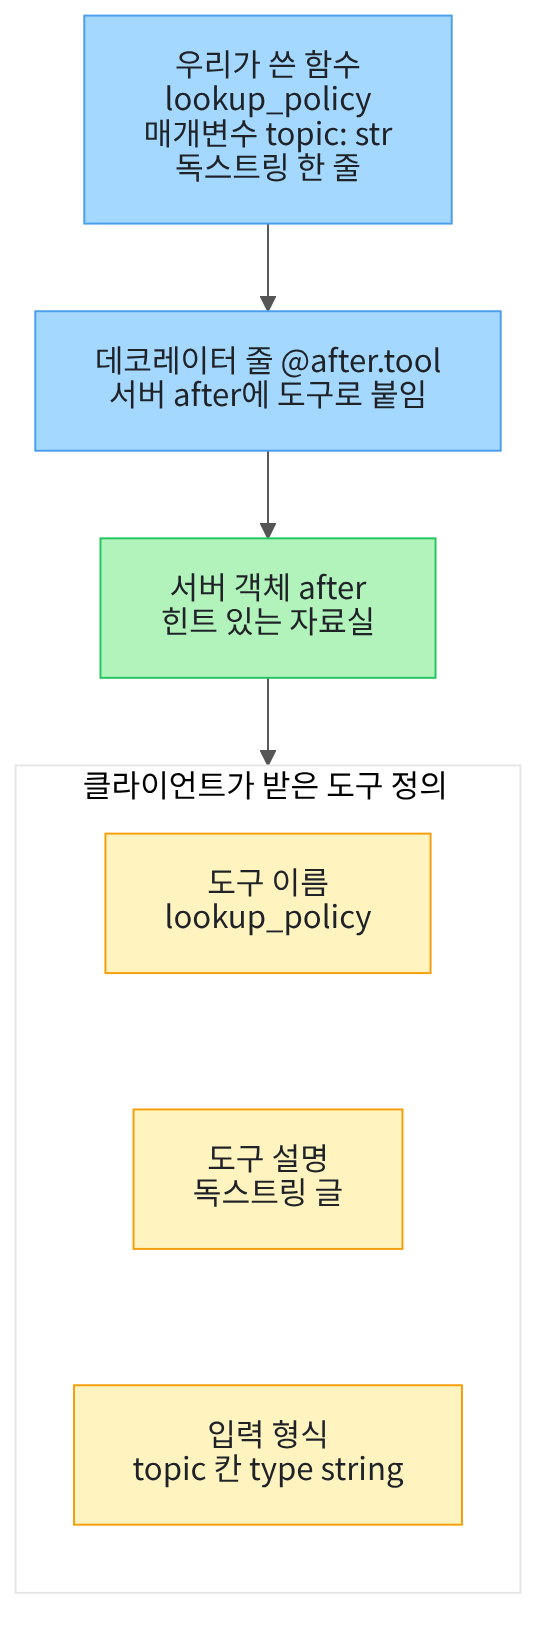

## 1. 준비

이 절은 파이썬 함수로 MCP 서버를 만드는 쪽을 봅니다.
제목의 FastMCP는 이 챕터가 쓰는 패키지 fastmcp와, 그 안의 서버 클래스 이름입니다.
「로컬 서버」는 같은 컴퓨터에서 도는 서버이고, 이 절의 서버는 같은 노트북 안에서 돕니다.

첫 셀은 패키지 둘을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastmcp==4.0.3" "mcp==2.2.0"
from importlib.metadata import version

print("fastmcp:", version("fastmcp"))
print("mcp:", version("mcp"))

Note: you may need to restart the kernel to use updated packages.


fastmcp: 4.0.3
mcp: 2.2.0


**결과 읽기** — 출력 줄 `fastmcp: 4.0.3`과 `mcp: 2.2.0`이 보입니다.
01절과 같은 판이고, 실습 폴더 잠금과도 같습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `logging`·`os`·`runpy`는 Python에 들어 있는 모듈입니다.
오류 종류 `ToolError`는 도구를 부르다 오류가 나면 클라이언트가 받는 오류입니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(logging·os·runpy는 Python에 들어 있는 모듈입니다)
import logging
import os
import runpy
from fastmcp import Client, FastMCP
from fastmcp.exceptions import ToolError

print("가져온 fastmcp 이름:", "Client, FastMCP, ToolError")

가져온 fastmcp 이름: Client, FastMCP, ToolError


**결과 읽기** — 출력 줄 `가져온 fastmcp 이름: Client, FastMCP, ToolError`가 보입니다.
이 노트북에도 API 키를 확인하는 셀은 없습니다.

도구 몸통에서 오류가 나면, FastMCP 서버는 오류 기록을 여러 줄로 남깁니다.
기록에는 시각과 파일 위치가 들어 있고, 표준 오류로 나갑니다.
이 절은 서버와 클라이언트가 같은 노트북에 있어서, 그 기록이 셀 출력에 섞입니다.
다음 셀은 모듈 `logging`으로 서버 쪽 기록을 막습니다.

In [3]:
# 서버 쪽 오류 기록이 셀 출력에 섞이지 않게, 이름이 fastmcp인 기록기의 수준을 올립니다
fastmcp_logger = logging.getLogger("fastmcp")
fastmcp_logger.setLevel(logging.CRITICAL)
print("fastmcp 기록기의 수준:", logging.getLevelName(fastmcp_logger.level))

fastmcp 기록기의 수준: CRITICAL


**결과 읽기** — 출력 줄 `fastmcp 기록기의 수준: CRITICAL`이 보입니다.
함수 `logging.getLogger`는 이름으로 기록기(logger)를 찾아 내놓습니다.
기록기는 정한 수준보다 낮은 기록을 남기지 않고, 이제 가장 높은 수준의 기록만 남깁니다.
막은 것은 서버 쪽 기록뿐이고, 클라이언트는 오류를 그대로 `ToolError`로 받습니다.

막지 않으면 3절의 잘못된 호출 하나에 기록이 27줄, 4절의 호출 하나에 경고 기록이 5줄 나왔습니다.
줄 수는 화면 폭 80칸에서 센 값이고, 노트북 밖의 작은 스크립트로 확인했습니다.

## 2. 서버를 만들고 도구 붙이기

01절에서는 서버 파일이 만든 서버에 붙어, 구성 요소 셋을 받았습니다.
이 절은 서버를 만드는 쪽에서, 서버 파일에 있던 붙이는 줄을 노트북에 직접 씁니다.
먼저 도구가 찾아 줄 자료를 만듭니다.
서버 파일 `course_server.py`의 규정 셋 가운데 둘을 같은 글로 옮긴 딕셔너리입니다.

In [4]:
# 도구가 찾아 줄 자료실 규정 두 가지를 딕셔너리로 만듭니다(서버 파일의 규정과 같은 글)
rules = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
}
print("규정 주제:", list(rules))

규정 주제: ['대출', '운영']


**결과 읽기** — 출력 줄 `규정 주제: ['대출', '운영']`이 보입니다.
딕셔너리를 `list`에 넣으면 키만 차례대로 모인 목록이 됩니다.

다음 셀은 연습용 서버 객체를 만듭니다.
01절 6절의 빈 서버처럼, 클래스 `FastMCP`에 서버 이름 하나만 넘깁니다.

In [5]:
# 연습용 서버 객체를 만듭니다(01절 6절의 빈 서버처럼 서버 이름 하나만 넘깁니다)
practice = FastMCP("연습 자료실")
print("서버 이름:", practice.name)

서버 이름: 연습 자료실


**결과 읽기** — 출력 줄 `서버 이름: 연습 자료실`이 보입니다.
01절 6절에서 본 것처럼, 이 서버에는 아직 붙인 것이 없습니다.

다음 셀은 규정 수를 알려 주는 평범한 함수를 만듭니다.
함수 이름 아래 줄의 글은 독스트링이고, Ch 19 01절에서 도구 설명이 되었던 글입니다.
이 함수는 아직 서버에 붙이지 않습니다.

In [6]:
# 규정 수를 알려 주는 평범한 함수를 만듭니다(서버에는 아직 붙이지 않습니다)
def count_rules():
    """자료실에 적힌 규정 수를 알려 줍니다."""
    return len(rules)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `count_rules`는 노트북 안에만 있고, 서버 `practice`는 이 함수를 모릅니다.

다음 셀은 서버에 연결해 도구 하나를 부르는 함수를 만듭니다.
이 절은 도구를 여러 번 부르므로, 연결하고 부르고 결과를 담는 일을 함수 하나로 묶습니다.
함수 안에서 await를 쓰므로, 정의 줄을 Ch 2 12절처럼 `async def`로 씁니다.
오류가 나면 Ch 2 05절처럼 오류 이름 `ToolError`만 받아, 셀이 멈추지 않게 합니다.
받은 글은 메서드 `splitlines`로 줄마다 나눈 목록으로 담습니다.

In [7]:
# 서버에 연결해 도구 하나를 부르고, 받은 결과나 오류를 한국어 키 딕셔너리로 내놓습니다
async def call_tool_row(server, tool_name, arguments):
    async with Client(server) as client:
        try:
            result = await client.call_tool(tool_name, arguments)
            row = {"받은 것": "결과", "글 줄": result.content[0].text.splitlines()}
        except ToolError as error:
            # 받은 오류의 종류 이름과, 오류 글을 줄마다 나눈 목록을 담습니다
            row = {"받은 것": type(error).__name__, "글 줄": str(error).splitlines()}
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
결과를 받으면 키 「받은 것」의 값이 「결과」이고, 오류를 받으면 오류 종류 이름입니다.
연결은 함수 안의 `async with` 블록을 벗어날 때 닫힙니다.
이 함수를 부르는 줄도 셀 맨 위에 await를 붙여 씁니다.

다음 셀은 연습 서버의 도구 목록을 받고, 붙이지 않은 함수 이름으로 도구를 불러 봅니다.
실행 전에 예상해 봅니다.
노트북에 함수 `count_rules`가 있으니, 서버도 이 이름의 도구를 찾을까요?

In [8]:
# 연습 서버의 도구 목록을 받고, 붙이지 않은 함수 이름으로 도구를 불러 봅니다
async with Client(practice) as client:
    practice_tools = await client.list_tools()
print("받은 도구 수:", len(practice_tools))
plain_row = await call_tool_row(practice, "count_rules", {})
print("도구를 부른 결과:", plain_row)

받은 도구 수: 0
도구를 부른 결과: {'받은 것': 'ToolError', '글 줄': ["Unknown tool: 'count_rules'"]}


**결과 읽기** — 출력 줄 `받은 도구 수: 0`이 보입니다.
도구를 부른 결과는 `ToolError`이고, 받은 글은 `Unknown tool: 'count_rules'`입니다.
서버는 이름이 `count_rules`인 도구를 모른다고 답했습니다.
노트북에 함수가 있어도, 서버에 붙이지 않으면 클라이언트는 찾지 못합니다.

다음 셀은 같은 함수 위에 줄 하나 `@practice.tool`만 더해 다시 정의합니다.
함수 위의 `@` 줄은 데코레이터 줄이고, 아래 함수를 만든 뒤 곧바로 `@` 뒤의 것에 넘기는 표시입니다.
행사 명단에 이름을 올려야 입구에서 찾아지는 것과 비슷합니다.
이 줄은 아래 함수를 서버 `practice`의 도구로 등록합니다.
데코레이터 줄의 뜻은 Ch 2 09절에 있고, Ch 19 01절의 `@tool`도 같은 모양이었습니다.

In [9]:
# 데코레이터 줄 하나만 더해, 같은 함수를 연습 서버의 도구로 붙입니다
@practice.tool
def count_rules():
    """자료실에 적힌 규정 수를 알려 줍니다."""
    return len(rules)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 이름·독스트링·몸통은 앞 판과 같고, 다른 것은 데코레이터 줄 하나입니다.
줄 끝에 괄호가 없는 `@practice.tool`은 인자 없이 붙이는 모양입니다.

다음 셀은 다시 연결해 도구 목록을 받고, 도구 정의를 봅니다.

In [10]:
# 다시 연결해 도구 목록을 받고, 첫 도구 정의의 이름·설명·입력 형식을 봅니다
async with Client(practice) as client:
    practice_tools = await client.list_tools()
count_tool = practice_tools[0]
print("받은 도구 수:", len(practice_tools))
print("도구 이름:", count_tool.name)
print("도구 설명:", count_tool.description)
print("입력 형식:", count_tool.input_schema)

받은 도구 수: 1
도구 이름: count_rules
도구 설명: 자료실에 적힌 규정 수를 알려 줍니다.
입력 형식: {'type': 'object', 'additionalProperties': False, 'properties': {}}


**결과 읽기** — 출력 줄 `받은 도구 수: 1`과 `도구 이름: count_rules`가 보입니다.
도구 이름은 함수 이름이고, 도구 설명은 독스트링 글입니다.
입력 형식의 `'properties': {}`는 받는 인자가 하나도 없다는 뜻입니다.
함수에 매개변수가 없기 때문입니다.

다음 셀은 붙인 도구를 클라이언트로 부릅니다.
노트북의 이름 `count_rules`가 무엇으로 남았는지도 봅니다.

In [11]:
# 붙인 도구를 클라이언트로 부르고, 노트북의 이름 count_rules가 무엇으로 남았는지 봅니다
practice_row = await call_tool_row(practice, "count_rules", {})
print("도구를 부른 결과:", practice_row)
print("노트북의 count_rules 종류:", type(count_rules).__name__)
print("함수로 바로 부른 값:", count_rules())

도구를 부른 결과: {'받은 것': '결과', '글 줄': ['2']}
노트북의 count_rules 종류: function
함수로 바로 부른 값: 2


**결과 읽기** — 도구를 부른 결과의 키 「받은 것」이 `'결과'`이고, 글 줄은 `['2']`입니다.
서버가 함수 `count_rules`를 실행해, 규정 수 2를 글로 보냈습니다.
출력 줄 `노트북의 count_rules 종류: function`과 `함수로 바로 부른 값: 2`도 보입니다.

Ch 19 01절의 `@tool`은 이름에 도구 객체를 남겨, 함수처럼 부르면 멈췄습니다.
이 절의 데코레이터 줄은 서버에 도구를 올리고, 노트북의 이름에는 함수를 그대로 둡니다.
01절 2절에서 서버 파일의 `lookup_policy`가 `function`이었던 것과 같은 모습입니다.
또 이 줄은 서버 객체의 메서드라서, 붙인 도구는 그 서버 하나에만 들어갑니다.

## 3. 힌트 없이 붙인 도구 (Before)

이제 인자를 받는 도구를 붙입니다.
Ch 2 07절에서 매개변수 힌트는 기대하는 자료형을 적은 표시일 뿐, 값을 검사하지 않았습니다.
그래서 힌트를 빼도 파이썬 함수는 잘 돕니다.

Ch 19 01절 7절은 힌트를 빼면 입력 형식에서 자료형이 빠지는 것까지 보고, 잘못된 값은 넣어 보지 않았습니다.
이 절 3·4절이 그 값을 넣어 봅니다.
다음 셀은 매개변수 `topic`에 힌트를 적지 않고, 독스트링도 없이 도구를 붙입니다.
몸통 첫 줄은 들어온 값을 목록 `body_inputs`에 적어, 값이 몸통까지 왔는지 나중에 보게 합니다.

In [12]:
# Before: 매개변수 힌트와 독스트링 없이, 규정을 찾는 도구를 붙인 서버를 만듭니다
before = FastMCP("힌트 없는 자료실")
# 몸통에 들어온 값을 적어 둘 빈 목록입니다
body_inputs = []

@before.tool
def lookup_policy(topic):
    body_inputs.append(topic)
    return rules[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 셀의 `@before.tool` 줄은 아래 함수를 서버 `before`의 도구로 등록합니다.
몸통은 딕셔너리 `rules`에서 주제 글을 찾아 내놓고, 없는 키면 파이썬 오류 `KeyError`가 납니다.

다음 셀은 이 도구의 정의에서 설명과 입력 형식을 봅니다.

In [13]:
# Before 서버에 연결해 도구 정의의 이름·설명·입력 형식을 봅니다
async with Client(before) as client:
    before_tools = await client.list_tools()
before_tool = before_tools[0]
print("도구 이름:", before_tool.name)
print("도구 설명:", before_tool.description)
print("입력 형식:", before_tool.input_schema)

도구 이름: lookup_policy
도구 설명: None
입력 형식: {'type': 'object', 'additionalProperties': False, 'properties': {'topic': {}}, 'required': ['topic']}


**결과 읽기** — 출력 줄 `도구 설명: None`이 보입니다.
라벨 `입력 형식:` 뒤에 `'topic': {}`와 `'required': ['topic']`이 있습니다.
인자 `topic`이 꼭 있어야 한다는 것은 적혔지만, 어떤 값이어야 하는지는 빈 칸입니다.
빈 칸 `{}`는 아무 값이나 받는다는 뜻입니다.

다음 셀은 맞는 값 `"대출"`을 넣어 부릅니다.
부르기 전에 목록 `body_inputs`를 비워, 이 호출에서 몸통에 들어온 값만 보이게 합니다.

In [14]:
# 맞는 값 "대출"을 넣어 부르고, 몸통에 들어온 값을 봅니다(부르기 전에 목록을 비웁니다)
body_inputs = []
before_ok = await call_tool_row(before, "lookup_policy", {"topic": "대출"})
print("도구를 부른 결과:", before_ok)
print("몸통에 들어온 값:", body_inputs)

도구를 부른 결과: {'받은 것': '결과', '글 줄': ['일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.']}
몸통에 들어온 값: ['대출']


**결과 읽기** — 받은 것은 `'결과'`이고, 글 줄에 대출 규정 한 문장이 있습니다.
출력 줄 `몸통에 들어온 값: ['대출']`로, 값이 몸통까지 들어가 규정을 찾았습니다.
맞는 값을 넣으면 힌트가 없어도 도구는 잘 돕니다.

다음 셀은 글이 아닌 값 `3`을 넣어 부릅니다.
모델이 인자를 잘못 채운 요청과 같은 상황입니다.
실행 전에 예상해 봅니다.
입력 형식이 빈 칸이니, 값 3은 몸통까지 들어갈까요?

In [15]:
# 글이 아닌 값 3을 넣어 부르고, 받은 오류와 몸통에 들어온 값을 봅니다
body_inputs = []
before_bad = await call_tool_row(before, "lookup_policy", {"topic": 3})
print("받은 것:", before_bad["받은 것"])
print("받은 글:", before_bad["글 줄"])
print("몸통에 들어온 값:", body_inputs)

받은 것: ToolError
받은 글: ["Error calling tool 'lookup_policy': 3"]
몸통에 들어온 값: [3]


**결과 읽기** — 받은 것은 `ToolError`이고, 받은 글은 `Error calling tool 'lookup_policy': 3` 한 줄입니다.
출력 줄 `몸통에 들어온 값: [3]`으로, 값 3이 몸통까지 들어갔습니다.
몸통의 `rules[topic]`이 키 3을 찾지 못해 `KeyError`가 났고, 서버가 그 오류를 `ToolError`로 보냈습니다.

이것이 이 절의 Before 결함입니다.
받은 글에는 찾지 못한 키 3만 있어, 무엇을 넣어야 하는지 알려 주지 않습니다.
입력 형식이 빈 칸이라 서버가 값을 미리 보지 못하고, 몸통 첫 줄도 잘못된 값으로 실행됐습니다.
몸통 앞부분에 되돌리기 어려운 일이 있었다면, 그 일도 잘못된 값으로 실행됐을 것입니다.

## 4. 힌트와 독스트링을 적어 붙인 도구 (After)

After 도구는 몸통을 그대로 두고, 매개변수 `topic`에 힌트 `: str`을 적습니다.
함수 이름 아래에는 무엇을 넣어야 하는지 적은 독스트링을 둡니다.
서버 이름만 「힌트 있는 자료실」로 다르고, 도구 이름은 Before와 같은 `lookup_policy`입니다.

이 챕터는 서버에 붙이는 도구 함수의 매개변수에만 `: str` 같은 단순한 힌트를 적습니다.
서버 클래스 FastMCP가 이 힌트로 입력 형식을 만들고, 그 입력 형식이 이 절에서 배울 내용이기 때문입니다.
Ch 19 01절의 `@tool` 함수에 `: str`을 적은 것과 같은 까닭이고, 내놓는 값 힌트(`-> str`)는 적지 않습니다.

In [16]:
# After: 몸통은 그대로 두고, 매개변수 힌트 topic: str과 독스트링을 적어 붙인 서버를 만듭니다
after = FastMCP("힌트 있는 자료실")

@after.tool
def lookup_policy(topic: str):
    """자료실 규정 한 가지를 찾아 알려 줍니다. topic에는 대출이나 운영을 넣습니다."""
    body_inputs.append(topic)
    return rules[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 셀의 `@after.tool` 줄은 아래 함수를 서버 `after`의 도구로 등록합니다.
노트북의 이름 `lookup_policy`는 이제 After 함수를 가리키고, 서버 `before`는 자기 도구를 그대로 가집니다.

다음 셀은 After 도구의 정의를 봅니다.

In [17]:
# After 서버에 연결해 도구 정의의 이름·설명·입력 형식을 봅니다
async with Client(after) as client:
    after_tools = await client.list_tools()
after_tool = after_tools[0]
print("도구 이름:", after_tool.name)
print("도구 설명:", after_tool.description)
print("입력 형식:", after_tool.input_schema)

도구 이름: lookup_policy
도구 설명: 자료실 규정 한 가지를 찾아 알려 줍니다. topic에는 대출이나 운영을 넣습니다.
입력 형식: {'type': 'object', 'additionalProperties': False, 'properties': {'topic': {'type': 'string'}}, 'required': ['topic']}


**결과 읽기** — 라벨 `도구 설명:` 뒤에 독스트링 글이 보입니다.
라벨 `입력 형식:` 뒤에는 `'topic': {'type': 'string'}`이 있습니다.
Before 도구의 빈 칸 `{}` 자리에, 인자 `topic`은 글이어야 한다는 규칙이 들어갔습니다.
칸 `'required': ['topic']`과 `'additionalProperties': False`는 Before와 같습니다.

다음 셀은 Before와 같은 값 `3`을 넣어 부릅니다.
실행 전에 예상해 봅니다.
이번에도 값 3이 몸통까지 들어갈까요?

In [18]:
# Before와 같은 값 3을 넣어 부르고, 받은 오류와 몸통에 들어온 값을 봅니다
body_inputs = []
after_bad = await call_tool_row(after, "lookup_policy", {"topic": 3})
print("받은 것:", after_bad["받은 것"])
print("받은 글의 줄 수:", len(after_bad["글 줄"]))
print("받은 글의 앞 세 줄:")
for line in after_bad["글 줄"][:3]:
    print(line)
print("몸통에 들어온 값:", body_inputs)

받은 것: ToolError
받은 글의 줄 수: 4
받은 글의 앞 세 줄:
1 validation error for call[lookup_policy]
topic
  Input should be a valid string [type=string_type, input_value=3, input_type=int]
몸통에 들어온 값: []


**결과 읽기** — 받은 것은 이번에도 `ToolError`이고, 출력 줄 `받은 글의 줄 수: 4`가 보입니다.
앞 세 줄은 `1 validation error for call[lookup_policy]`, `topic`, `Input should be a valid string`으로 시작합니다.
출력 줄 `몸통에 들어온 값: []`으로, 몸통은 실행되지 않았습니다.
서버가 입력 형식에 맞춰 값을 먼저 보고, 글이 아니라서 몸통 전에 거절했습니다.

이것이 Ch 19 02절의 입력 검사이고, 이 절에서는 FastMCP 서버가 검사합니다.
받은 글은 어느 인자가 무엇이어야 하는지 알려 줍니다.
두 판은 힌트와 독스트링이 함께 달랐지만, 거절을 가른 것은 입력 형식의 `topic` 칸입니다.
독스트링은 도구 설명만 바꿨습니다.
넷째 줄은 검사를 맡은 라이브러리 pydantic의 안내 주소라서 출력하지 않았습니다.

In [19]:
# 맞는 값 "대출"을 넣어, After 도구도 Before와 같은 결과를 내는지 봅니다
body_inputs = []
after_ok = await call_tool_row(after, "lookup_policy", {"topic": "대출"})
print("받은 것:", after_ok["받은 것"])
print("결과 글이 Before와 같은가:", after_ok["글 줄"] == before_ok["글 줄"])
print("몸통에 들어온 값:", body_inputs)

받은 것: 결과
결과 글이 Before와 같은가: True
몸통에 들어온 값: ['대출']


**결과 읽기** — 출력 줄 `결과 글이 Before와 같은가: True`와 `몸통에 들어온 값: ['대출']`이 보입니다.
힌트를 적어도 맞는 값은 그대로 몸통까지 가서, Before와 같은 규정을 찾았습니다.
힌트와 독스트링이 바꾼 것은 잘못된 값이 멈추는 자리와, 클라이언트가 받는 도구 정의입니다.

## 5. 값 바꿔 보기: 글이지만 없는 주제

넣는 값 하나만 바꿔 봅니다.
바꿀 값은 인자 `topic`이고, 글이지만 `rules`에 없는 주제 `"주차"`를 넣습니다.
두 도구를 차례로 부르고, 몸통에 들어온 값을 봅니다.
실행 전에 예상해 봅니다.
After 도구의 입력 형식은 이 값을 거절할까요?

In [20]:
# 넣는 값만 "주차"로 바꿔, Before와 After 도구를 차례로 부릅니다
body_inputs = []
before_park = await call_tool_row(before, "lookup_policy", {"topic": "주차"})
after_park = await call_tool_row(after, "lookup_policy", {"topic": "주차"})
print("Before에서 받은 글:", before_park["글 줄"])
print("After에서 받은 글:", after_park["글 줄"])
print("몸통에 들어온 값:", body_inputs)

Before에서 받은 글: ["Error calling tool 'lookup_policy': '주차'"]
After에서 받은 글: ["Error calling tool 'lookup_policy': '주차'"]
몸통에 들어온 값: ['주차', '주차']


**결과 읽기** — 두 도구 모두 받은 글이 `Error calling tool 'lookup_policy': '주차'`입니다.
출력 줄 `몸통에 들어온 값: ['주차', '주차']`로, 두 번 모두 몸통까지 들어갔습니다.
After 도구의 입력 형식은 글인지만 보므로, 글 `"주차"`는 검사를 지났습니다.

힌트 `: str`이 정하는 것은 값의 자료형입니다.
어느 주제를 받을지는 입력 형식에 적히지 않아, 몸통이 따로 검사해야 합니다.
Ch 19 02절에서도 입력 검사는 값이 규칙 안에 있는지만 보았습니다.
6절은 서버 파일의 도구가 이 검사를 어디서 하는지 봅니다.

## 6. 서버 파일의 붙이는 줄

01절에서 읽은 서버 파일 `course_server.py`에도 붙이는 줄이 셋 있습니다.
도구는 `@mcp.tool(tags={"public", "read"})` 줄, 자료는 `@mcp.resource("policy://handbook")` 줄로 붙입니다.
메시지 틀은 `@mcp.prompt` 줄로 붙이고, 이 줄은 괄호가 없는 모양입니다.
괄호 안의 인자는 붙이면서 함께 정하는 값이고, 자료 줄의 글은 01절에서 본 자료 주소가 되었습니다.
다음 셀은 01절 2절과 같은 셀로 서버 파일의 위치를 찾습니다.

In [21]:
# 작업 폴더에서 본 서버 파일의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["../course_server.py", "course_server.py", "labs/part6/ch28-mcp/course_server.py"]
server_file = None
for candidate in candidates:
    if os.path.exists(candidate):
        server_file = candidate
        break
print("서버 파일을 찾았는가:", server_file is not None)
print("고른 파일 위치:", server_file)
assert server_file is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

서버 파일을 찾았는가: True
고른 파일 위치: labs/part6/ch28-mcp/course_server.py


**결과 읽기** — 출력 줄 `서버 파일을 찾았는가: True`가 보입니다.
교재 출력은 프로젝트 맨 위에서 실행해 셋째 후보 `labs/part6/ch28-mcp/course_server.py`를 골랐습니다.
`notebooks/` 폴더에서 열면 첫 후보 `../course_server.py`가 골라집니다.

다음 셀은 01절 2절처럼 함수 `runpy.run_path`로 서버 파일을 실행해, 서버 객체를 받습니다.

In [22]:
# 서버 파일을 실행해, 그 파일이 만든 서버 객체 mcp를 받습니다(01절 2절처럼 runpy.run_path로 읽습니다)
server_names = runpy.run_path(server_file)
server = server_names["mcp"]
print("서버 이름:", server.name)

서버 이름: 교육센터 자료실


**결과 읽기** — 출력 줄 `서버 이름: 교육센터 자료실`이 보입니다.
01절에서 본 것처럼, 이 함수로 읽으면 서버 파일 맨 끝의 실행 줄은 돌지 않습니다.
그 줄 `mcp.run(transport="stdio")`는 파일을 다른 프로그램으로 띄울 때 쓰고, 이 절에서는 실행하지 않습니다.

다음 셀은 서버 파일 도구의 정의에서 입력 형식·출력 형식·꼬리표를 봅니다.

In [23]:
# 서버 파일 도구의 정의에서 인자 topic의 입력 형식, 출력 형식, 꼬리표를 봅니다
async with Client(server) as client:
    server_tools = await client.list_tools()
file_tool = server_tools[0]
print("topic의 입력 형식:", file_tool.input_schema["properties"]["topic"])
print("출력 형식:", file_tool.output_schema)
print("After 도구의 출력 형식:", after_tool.output_schema)
print("꼬리표:", file_tool.meta)

topic의 입력 형식: {'type': 'string'}
출력 형식: {'properties': {'result': {'type': 'string'}}, 'required': ['result'], 'type': 'object', 'x-fastmcp-wrap-result': True}
After 도구의 출력 형식: None
꼬리표: {'fastmcp': {'tags': ['public', 'read']}}


**결과 읽기** — 출력 줄 `topic의 입력 형식: {'type': 'string'}`이 보입니다.
서버 파일도 매개변수 힌트 `topic: str`로 After와 같은 입력 형식을 만들었습니다.
라벨 `출력 형식:` 뒤에는 칸 `result`에 글을 담는다는 형식이 있고, After 도구는 `None`입니다.
라벨 `꼬리표:` 뒤에는 `'tags': ['public', 'read']`가 있습니다.

출력 형식은 서버 파일 함수의 내놓는 값 힌트 `-> str`에서 만들어졌습니다.
도구가 내놓는 값의 모양을 알리는 정보이고, 이 챕터에서 붙이는 도구는 내놓는 값 힌트를 적지 않아 만들지 않습니다.
꼬리표는 데코레이터 줄의 인자 `tags`가 도구에 붙인 이름표이고, 이 절에서는 꼬리표로 아무것도 하지 않습니다.

다음 셀은 서버 파일의 도구에 5절의 값 `"주차"`를 넣어 부릅니다.

In [24]:
# 서버 파일의 도구에도 "주차"를 넣어 부르고, 받은 글을 봅니다
file_park = await call_tool_row(server, "lookup_policy", {"topic": "주차"})
print("받은 것:", file_park["받은 것"])
print("받은 글:", file_park["글 줄"])

받은 것: ToolError
받은 글: ["Error calling tool 'lookup_policy': topic은 대출, 운영, 연체 중 하나여야 합니다."]


**결과 읽기** — 받은 것은 `ToolError`이고, 받은 글에 `topic은 대출, 운영, 연체 중 하나여야 합니다.`가 있습니다.
서버 파일의 몸통 첫 줄이 주제가 규정에 있는지 보고, 없으면 이 글로 오류를 냅니다.
5절의 `'주차'` 한 단어보다, 무엇을 넣어야 하는지 알려 주는 글입니다.

자료형은 입력 형식이 몸통 전에 검사하고, 허용하는 주제는 몸통 첫 줄이 검사합니다.
몸통의 검사 줄은 파이썬 오류 `ValueError`를 내고, 서버는 그 글을 `ToolError`로 보냈습니다.

## 정리

1. 데코레이터 줄 하나로 함수가 도구가 되었고, 함수 이름과 독스트링이 도구 이름과 설명이 되었습니다.
2. 힌트 없이 붙인 도구는 입력 형식이 빈 칸이라, 값 3이 몸통까지 들어가 뜻 모를 오류를 냈습니다.
3. 힌트를 적자 같은 값이 몸통 전에 거절되었고, 없는 주제는 서버 파일처럼 몸통이 검사해야 했습니다.

03절에서는 서버를 다른 프로그램으로 띄워 연결하고, 서버에 넘기는 값과 권한의 경계를 봅니다.